# Affine drift correction for two orthogonal gold scans

Fit the drift from full-detector virtual images, compare the corrected diffraction data, and inspect where each probe landed in the 0° scan frame.

## Install the notebook environment

**Release status.** The saved results use the subpixel fix in [QuantEM PR #283](https://github.com/electronmicroscopy/quantem/pull/283/commits/75693af69d2efb4a5717f718a3a9c8c4f34b3019), GPU RC18 and Widget RC44. The commands below target their public releases. The core version pin is provisional until publication.

From a terminal, create the environment once.

```bash
conda create -n gold-drift python=3.12 pip -y
conda activate gold-drift
```

**Apple silicon Mac (MPS)**

```bash
python -m pip install --extra-index-url https://test.pypi.org/simple \
  "quantem==0.1.11rc1" "quantem.widget[mps]==0.0.1rc44" "quantem.gpu[mps]==0.0.1rc18" jupyterlab ipykernel
```

**Linux with an NVIDIA GPU (CUDA)**

```bash
python -m pip install --extra-index-url https://test.pypi.org/simple \
  "quantem==0.1.11rc1" "quantem.widget[cuda]==0.0.1rc44" "quantem.gpu[cuda]==0.0.1rc18" jupyterlab ipykernel
```

Open this notebook in VS Code and select the **gold-drift** Python environment, or run `jupyter lab` in the activated environment. Leave `device = 0` for MPS or the first visible NVIDIA GPU. On a multi-GPU system, set it to the visible GPU index you want.

## Data

Download both masters (`gold_019_master.h5` and `gold_020_master.h5`) and all seven data files for each scan. Keep the 16 files together in `tutorials/imaging/drift/data/gold_4dstem/` and run the notebook from `tutorials/imaging/drift/`. [Download the gold scans](https://drive.google.com/drive/folders/1--5UhA1nF6Q0k-wPMjjowjvlJmnHm2t7?usp=sharing)

In [1]:
from pathlib import Path

import quantem.widget as qw
from quantem.gpu import io
from quantem.imaging import DriftCorrection

DATA = Path("data/gold_4dstem")
RESULT = DATA / "drift.zip"
PIXEL_SIZE_NM = 0.29771
device = 0  # Apple GPU or first visible NVIDIA GPU.

## Inspect the automatically selected compute backend

In [2]:
qw.profile()

Kernel          Unknown
quantem.widget  0.0.1rc44
  install       installed package
  commit        not recorded
quantem.gpu     0.0.1rc18
  install       installed package
  commit        not recorded
quantem         0.1.11rc1
  install       source override (differs from installed metadata)
  commit        75693af69d2e
  branch        drift-subpixel-registration
  workspace     linked worktree
webgpu kernels  quantem.gpu None, pinned c6bab78631db609edbced5ebe4d0b1b4b5151114
torch           2.15.0  device=mps (Apple)
VRAM (MPS)      0.0 live / 0.0 driver GB
python          3.12.16


## 1. Load the two native acquisitions

The ARINA masters contain the detector counts but do not contain calibrated
scan sampling or scan-rotation metadata. The acquisition record identifies
`gold_019` as 0° and `gold_020` as 90°. Their transferred real-space
calibration is **0.29771 nm/pixel**, derived from the 76.214 nm Velox field of
view at the same 1.30 Mx magnification divided by the native 256-pixel scan.

The reader keeps the native detector counts and sets the four flagged detector pixels to zero.

In [3]:
scan_0 = io.load(DATA / "gold_019_master.h5", device=device, hot_pixel_correction="zero")
scan_90 = io.load(DATA / "gold_020_master.h5", device=device, hot_pixel_correction="zero")
scan_0, scan_90

Loaded 256 x 256 scan, 192 x 192 detector, Apple GPU, 1.4 s. ANS: 4.83 GB uncompressed to 3.30 GB resident on GPU. 4 bad pixels set to zero (hot_pixel_correction="none" keeps the recorded values).
Stored as uint16: every uint32 value fits in 16 bits, so every count reads back unchanged (dtype="native" reads uint32).


Loaded 256 x 256 scan, 192 x 192 detector, Apple GPU, 1.0 s. ANS: 4.83 GB uncompressed to 3.33 GB resident on GPU. 4 bad pixels set to zero (hot_pixel_correction="none" keeps the recorded values).
Stored as uint16: every uint32 value fits in 16 bits, so every count reads back unchanged (dtype="native" reads uint32).


(                                                        Value      Unit        Metadata
 Property                                                                               
 Source                    data/gold_4dstem/gold_019_master.h5                          
 Format                                           Not recorded                          
 Shape (scan, detector)                  256 × 256 × 192 × 192                          
 Data dtype                                             uint16                          
 ANS resident size                                    3.304381        GB  Loaded storage
 Uncompressed size                                    4.831838        GB   Shape × dtype
 Accelerating voltage                             Not recorded        kV    Not recorded
 Convergence semiangle                            Not recorded      mrad    Not recorded
 Scan step (row, col)                             Not recorded  angstrom    Not recorded
 Detector step (row, 

## 2. Fit the affine drift

The search starts on a coarse grid and refines the drift rate at the native scan resolution.

In [4]:
drift = DriftCorrection.from_4dstem(
    scan_0,
    scan_90,
    scan_direction_degrees=(0, 90),
    scan_sampling=PIXEL_SIZE_NM,
    scan_units="nm",
    device=str(scan_0.device),
)
drift.correct_affine(
    show_combined=False,
    show_scans=False,
    verbose=True,
)

correct_affine: prepared scanline knots automatically; padding=0.5, canvas=(384, 384), 0.29 s


correct_affine: automatic pyramid 8x, 5 native candidates, 0.23 s
Drift: (+0.02656, -0.12344) px/line; translation bound 64.0 px


## 3. Compare the scans before and after correction

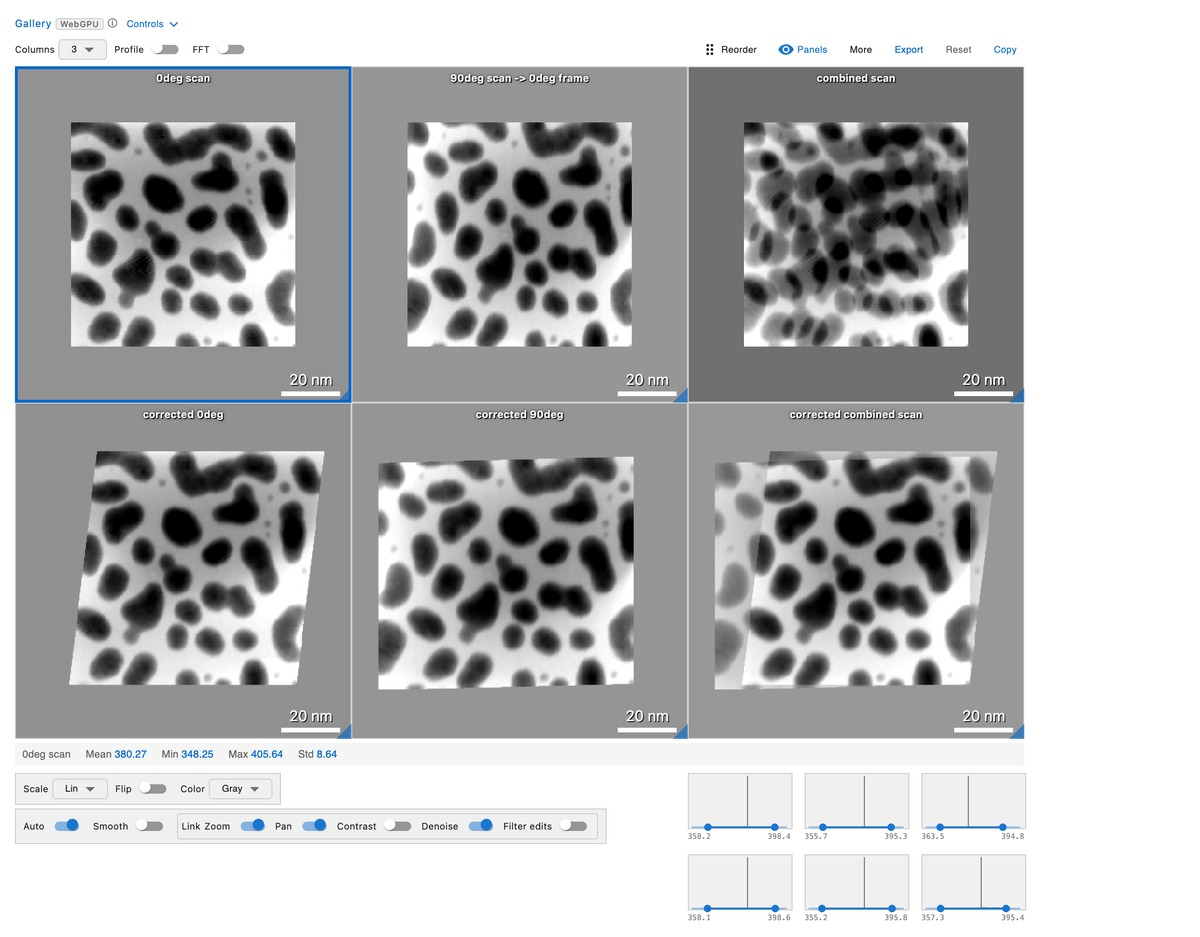

In [5]:
drift.show(cmap="gray", auto_contrast=True, link_contrast=False, size=360)

## 4. Verify the correction quantitatively

The report compares the scans before and after fitting on the same overlap mask. On this gold pair, all eight affine search stages selected the same drift rates on MPS and CUDA. Across 61,149 shared pixels, NCC increased from 0.071698 to 0.952293 on MPS and 0.952294 on CUDA.

In [6]:
quality = drift.report()
quality

,Common NCC,Top third,Middle third,Bottom third,Coverage
Mutual stage,,,,,
before,0.071698,-0.166422,-0.049514,0.165469,0.93306
affine,0.952293,0.966932,0.958999,0.977133,0.93306


## 5. Browse all three 4D-STEM processing stages

`show_4dstem()` constructs one labeled viewer containing the raw 0° dataset,
the affine-corrected 0° dataset, and the affine-corrected 0°/90°
diffraction-pattern average. `det_bin=4` affects only this browse copy.

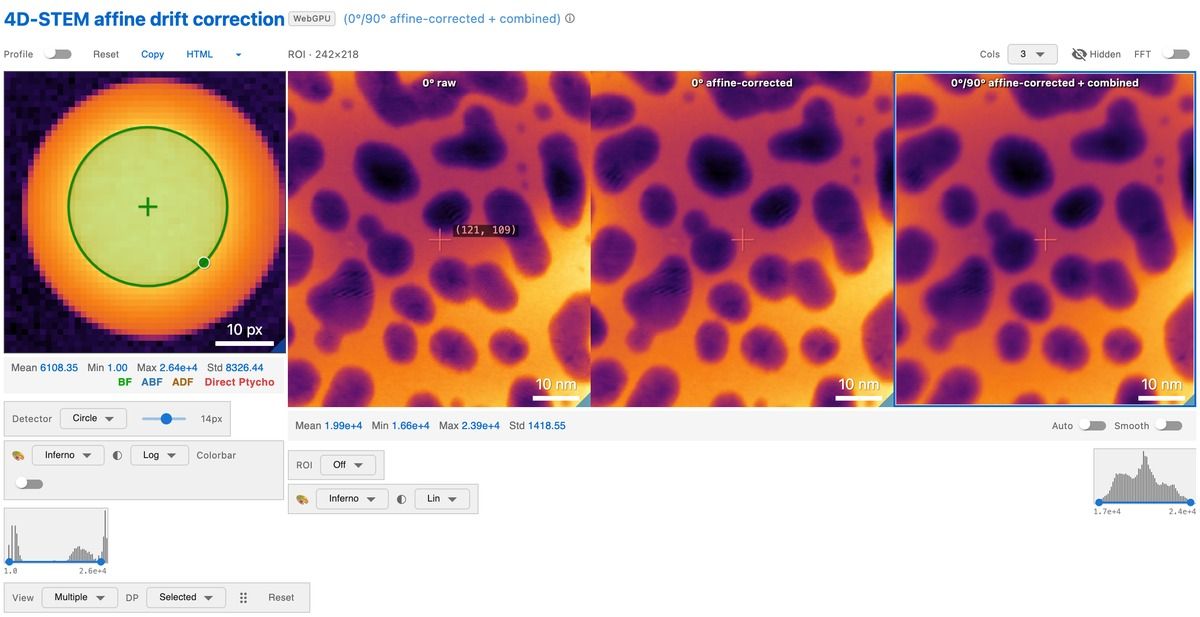

In [7]:
diffraction_view = drift.show_4dstem(det_bin=4, device=str(scan_0.device))
diffraction_view

## 6. Inspect the fitted probe positions

The 0° scan (left) and 90° scan (right) share the 0° reference frame. Arrows connect nominal sites (open circles) to fitted sites (blue dots). The plot shows every 16th site along each axis in pixels. The array retains every site in acquisition order, with (row, column) coordinates in ångströms.

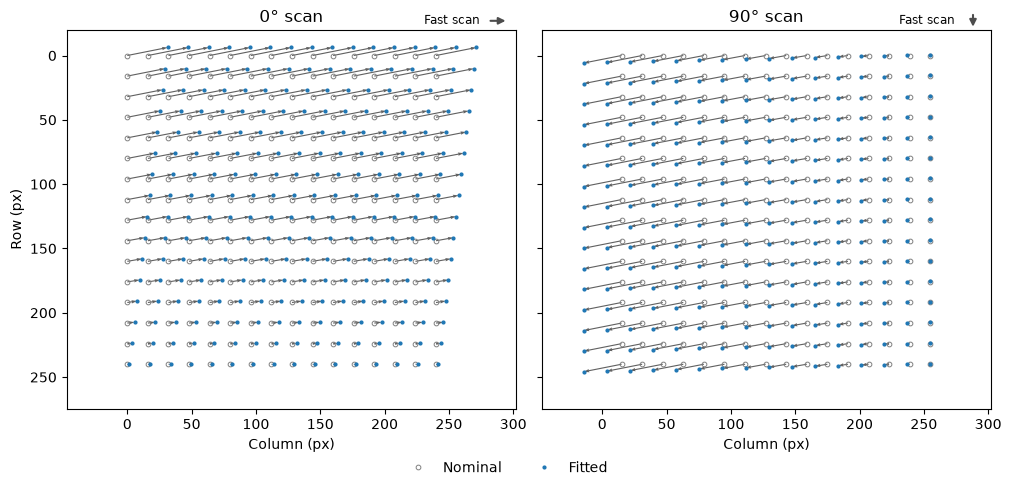

(2, 256, 256, 2)

In [8]:
positions_A = drift.probe_positions(show=True)
positions_A.shape

## 7. Save the fitted correction

Save the affine fit alongside the input files. The saved correction includes the fitted probe coordinates through `probe_positions()`.

In [9]:
drift.save(RESULT, mode="o")

## Full-resolution corrected diffraction data (optional)

To apply the fit to each native-resolution diffraction pattern, allow memory for both corrected scans and their merged result.

```python
full = drift.corrected_4dstem(verbose=True)
full.corrected_4dstem      # merged diffraction-pattern dataset
full.corrected_4dstem_0    # corrected 0° dataset
full.corrected_4dstem_1    # corrected 90° dataset in the 0° frame
```

## Continue with advanced tutorials

- **Explicit affine examples:** `advanced/2d_affine_explicit_*.ipynb`
- **Affine diagnostics:** `advanced/2d_affine_diagnostics_ws2_0070_0071.ipynb`